# 1_MNIST_CNN

Bản chuyển từ sample **2. CNN + MLP/1_MNIST_CNN.ipynb**. Chạy các ô theo thứ tự.

In [1]:
from pathlib import Path
from urllib.request import urlretrieve
import math
import numpy as np
import torch
from torch import nn
from torch.utils.data import DataLoader, Dataset, TensorDataset, Subset
from torchvision import transforms
from PIL import Image
import matplotlib.pyplot as plt

FULL = False  # True: dùng dữ liệu và số epoch theo sample
PROJECT = next((p for p in (Path.cwd(), *Path.cwd().parents)
                if (p / "HUONG_DAN.txt").is_file()), Path.cwd())
ROOT = PROJECT / "data"
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.manual_seed(2018)
torch.set_num_threads(min(4, torch.get_num_threads()))
results = {}

In [2]:
def epoch(model, loader, criterion, optimizer=None):
    training = optimizer is not None
    model.train(training)
    total_loss = correct = units = 0
    with torch.set_grad_enabled(training):
        for x, y in loader:
            x, y = x.to(DEVICE), y.to(DEVICE)
            if training:
                optimizer.zero_grad(set_to_none=True)
            out = model(x)
            if isinstance(criterion, nn.CrossEntropyLoss):
                assert out.argmax(1).shape == y.shape and y.dtype == torch.long
                correct += (out.argmax(1) == y).sum().item()
            else:
                assert out.shape == y.shape
            loss = criterion(out, y)
            if not torch.isfinite(loss):
                raise ValueError("Loss không hữu hạn")
            if training:
                loss.backward()
                optimizer.step()
            total_loss += loss.item() * y.numel()
            units += y.numel()
    return total_loss / units, correct / units

def fit(name, model, train, valid, criterion, opt, lr, epochs, batch,
        early=False, schedule=False, checkpoint=False, verbose=True):
    for layer in model.modules():
        if isinstance(layer, (nn.Conv2d, nn.Linear)):
            nn.init.xavier_uniform_(layer.weight)
            nn.init.zeros_(layer.bias)
    model.to(DEVICE)
    writer = None
    if checkpoint:
        from torch.utils.tensorboard import SummaryWriter
        writer = SummaryWriter("logs/" + name)
    optimizer = opt(model.parameters(), lr=lr)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, factor=0.1, patience=4, min_lr=1e-4,
        threshold=1e-4, threshold_mode="abs")
    loaders = [DataLoader(train, batch, shuffle=True), DataLoader(valid, batch)]
    best, stale = float("inf"), 0
    for step in range(1, epochs + 1):
        train_loss, _ = epoch(model, loaders[0], criterion, optimizer)
        val_loss, accuracy = epoch(model, loaders[1], criterion)
        if writer:
            writer.add_scalar("loss/train", train_loss, step)
            writer.add_scalar("loss/validation", val_loss, step)
            writer.add_scalar("accuracy/validation", accuracy, step)
        if val_loss < best:
            best, stale = val_loss, 0
            if checkpoint:
                torch.save(model.state_dict(), f"{name}_best.pt")
        else:
            stale += 1
        if schedule:
            scheduler.step(val_loss)
        if early and stale >= 5:
            break
    if writer:
        writer.close()
    if checkpoint:
        model.load_state_dict(torch.load(f"{name}_best.pt", map_location=DEVICE,
                                         weights_only=True))
        val_loss, accuracy = epoch(model, loaders[1], criterion)
    metric = accuracy if isinstance(criterion, nn.CrossEntropyLoss) else val_loss
    results[name] = (len(train), len(valid), step, val_loss, metric)
    if verbose:
        print(f"{name} | {step} epoch | train loss {train_loss:.5f} | "
              f"val loss {val_loss:.5f}", end="")
        if isinstance(criterion, nn.CrossEntropyLoss):
            print(f" | accuracy {accuracy:.2%}", end="")
        print()
    return model

In [3]:
def load_mnist():
    path = PROJECT / "mnist_mau.npz"
    sample = path.is_file() and not FULL
    if not sample:
        ROOT.mkdir(exist_ok=True, parents=True)
        path = ROOT / "mnist.npz"
        if not path.exists():
            tmp = path.with_suffix(".part")
            urlretrieve("https://storage.googleapis.com/tensorflow/tf-keras-datasets/mnist.npz", tmp)
            tmp.replace(path)
    with np.load(path) as data:
        rng = np.random.default_rng(2018)
        datasets = []
        for split, count in (("train", 4096), ("test", 1024)):
            x, y = data[f"x_{split}"], data[f"y_{split}"]
            if not FULL and not sample:
                indices = rng.choice(len(y), count, replace=False)
                x, y = x[indices], y[indices]
            datasets.append(TensorDataset(torch.from_numpy(x).unsqueeze(1).float() / 255,
                                          torch.from_numpy(y).long()))
        return tuple(datasets)

In [4]:
digits_train, digits_test = load_mnist()

In [5]:
def head(n_in, hidden, n_out, dropout):
    layers = [nn.Flatten()]
    for width in hidden:
        layers.extend([nn.Linear(n_in, width), nn.ReLU(), nn.Dropout(dropout)])
        n_in = width
    return nn.Sequential(*layers, nn.Linear(n_in, n_out))

def conv_block(n_in, channels, paddings, dropout):
    layers = []
    for width, padding in zip(channels, paddings, strict=True):
        layers.extend([nn.Conv2d(n_in, width, 3, padding=padding), nn.ReLU()])
        n_in = width
    return nn.Sequential(*layers, nn.MaxPool2d(2), nn.Dropout(dropout))

def digit_features():
    return nn.Sequential(conv_block(1, [64], [1], 0.2),
                         conv_block(64, [128], [1], 0.2),
                         conv_block(128, [256], [1], 0.2))

Sequential(
  (0): Sequential(
    (0): Sequential(
      (0): Conv2d(1, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): ReLU()
      (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
      (3): Dropout(p=0.2, inplace=False)
    )
    (1): Sequential(
      (0): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): ReLU()
      (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
      (3): Dropout(p=0.2, inplace=False)
    )
    (2): Sequential(
      (0): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): ReLU()
      (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
      (3): Dropout(p=0.2, inplace=False)
    )
  )
  (1): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=2304, out_features=512, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.2, inplace=False)
    (4): Linear(in_features=512, out_

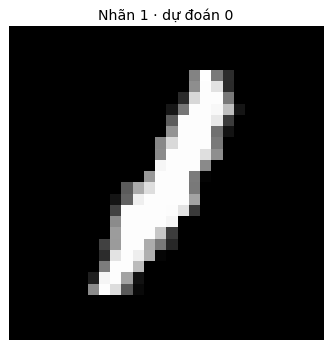

In [6]:
model = nn.Sequential(digit_features(), head(256 * 3 * 3, [512, 512], 10, 0.2))
print(model)
fit("MNIST", model, digits_train, digits_test, nn.CrossEntropyLoss(),
    torch.optim.SGD, 0.01, 30 if FULL else 3, 128)
x, label = digits_test[0]
with torch.inference_mode():
    probabilities = model(x[None].to(DEVICE)).softmax(1).cpu()
print("Kích thước", tuple(probabilities.shape), "| tổng xác suất", probabilities.sum().item())
plt.imshow(x.squeeze(), cmap="gray")
plt.title(f"Nhãn {label.item()} · dự đoán {probabilities.argmax().item()}")
plt.axis("off")
plt.show()

Chiếu dữ liệu huấn luyện xuống hai chiều bằng PCA cho ảnh thô, fc2 sau ReLU và pool3 sau global average pooling.

One-hot ví dụ: tensor([0, 0, 1])


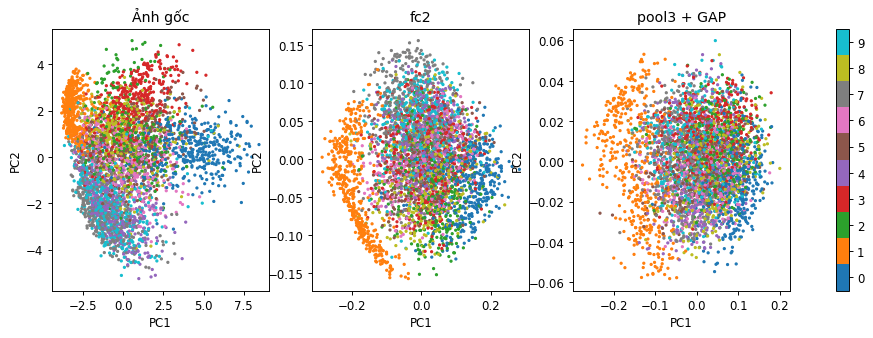

In [7]:
from sklearn.decomposition import PCA
print("One-hot ví dụ:", torch.nn.functional.one_hot(torch.tensor(2), 3))
raw, labels = digits_train.tensors
fc2, gap = [], []
with torch.inference_mode():
    for batch, _ in DataLoader(digits_train, 128):
        pool3 = model[0](batch.to(DEVICE))
        fc2.append(model[1][:6](pool3).cpu())
        gap.append(pool3.mean((2, 3)).cpu())
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, features, title in zip(axes, [raw.flatten(1), torch.cat(fc2), torch.cat(gap)],
                               ["Ảnh gốc", "fc2", "pool3 + GAP"]):
    coords = PCA(n_components=2, random_state=2018).fit_transform(features.numpy())
    dots = ax.scatter(*coords.T, c=labels, cmap="tab10", s=3, vmin=-0.5, vmax=9.5)
    ax.set(title=title, xlabel="PC1", ylabel="PC2")
fig.colorbar(dots, ax=axes, ticks=range(10))
plt.show()